# Nonlinear Regression – multiple data-sets

## Overview

This notebook extends the single data-set Michaelis–Menten workshop. It fits **several data-sets measured at the same substrate concentrations**, plots them all on one graph, and builds a table of Km and Vmax estimates (± standard error) for each data-set.

The steps are the same as before. The difference is that we put the fitting and plotting inside a `for` loop, so the same code runs once for each data-set.

1. Import libraries
2. Import the data (one column of substrate concentrations, one column per data-set)
3. Define the Michaelis–Menten function
4. Loop over the data-sets: fit with `curve_fit`, store the results, add the data and fitted curve to the plot
5. Tidy and save the plot
6. Display and save the results table

In [1]:
# Import the libraries and functions that you need

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import warnings  # Ignore this line and the next - they hide some harmless messages
warnings.filterwarnings('ignore', category=DeprecationWarning)

## Organising the data file

The data needs to be in **"wide" format** in your .csv file. The first column holds the substrate concentrations **in molar (M)**, headed `S`. Every other column holds the initial velocities for one data-set. The column heading becomes that data-set's name in the legend and the results table, so make it meaningful:

| S | Control | Inhibitor A | Inhibitor B |
|:---:|:---:|:---:|:---:|
| 0 | 0.000 | 0.000 | 0.000 |
| 0.0005 | 0.162 | 0.061 | 0.089 |
| ... | ... | ... | ... |

You can have as many data-set columns as you like. The code finds them automatically. If a value is missing, leave that cell blank and the code will skip that point for that data-set only.

In [2]:
# 1. Create a filehandle and import the data

datafile = os.path.join('MM_multi.csv')
MM_df = pd.read_csv(datafile)

# 2. The substrate concentrations are shared by every data-set

xdata = MM_df['S']

# 3. Every column except 'S' is a data-set. Make a list of their names

datasets = MM_df.columns.drop('S')
print('Data-sets found:', list(datasets))

MM_df.head()

Data-sets found: ['No inhibitor', 'Oxalate', 'Oxamate']


,S,No inhibitor,Oxalate,Oxamate
0,0.00000,0.245714,0.395714,0.165714
1,0.00025,1.202857,1.212857,0.737143
2,0.00060,1.848571,2.005714,1.202857
3,0.00150,3.630000,1.218571,2.650000
4,0.00250,3.961429,2.715714,3.158571


In [3]:
# Create the Michaelis-Menten function (unchanged from the single data-set notebook)

def MM(subsconc, Vmax, Km):
    Vo = (Vmax * subsconc) / (Km + subsconc)
    return Vo

## Fitting every data-set with a `for` loop

A `for` loop repeats a block of indented code once for each item in a list. Here the list is `datasets`. On each pass round the loop, the variable `name` holds the name of the next data-set, and the code:

1. picks out that data-set's velocities (`ydata`)
2. fits them with `curve_fit`
3. calculates the standard errors and an R² value
4. adds a row to a `results` list
5. plots the data points and the fitted curve in a matching colour

**Starting guesses (`p0`)**. With no starting values, `curve_fit` begins its search from Vmax = 1 and Km = 1. That worked for a single tidy data-set, but if your velocities or concentrations are on a very different scale it can fail or find a nonsense answer. We give it sensible guesses instead: the largest velocity measured as a guess for Vmax, and the middle substrate concentration as a guess for Km.

**Standard error, not standard deviation**. `np.sqrt(np.diag(pcov))` gives the *standard error* of each fitted parameter. It describes how precisely the fit pins down Vmax and Km from this one data-set. It is not the spread across repeated experiments.

**R²** is calculated the same way as for linear regression: 1 − (residual sum of squares ÷ total sum of squares). For nonlinear fits treat it as a rough guide only. Always look at the plot as well.

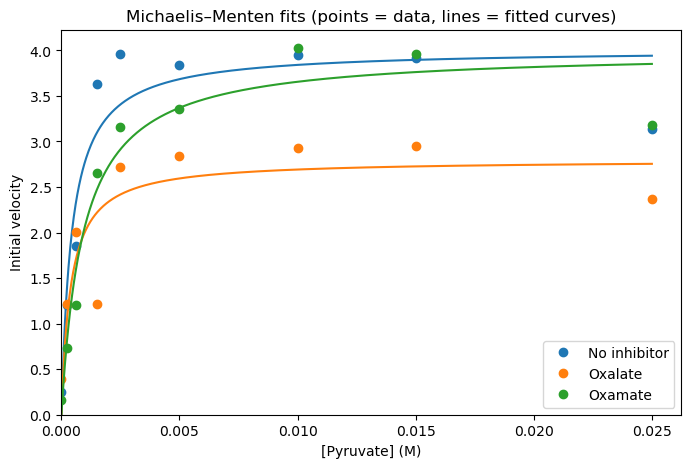

In [4]:
# An empty list to collect one row of results per data-set
results = []

# 1000 evenly spaced x-values for drawing smooth fitted curves
x_smooth = np.linspace(0, xdata.max(), 1000)

# Set up one figure to hold every data-set
fig, ax = plt.subplots(figsize=(8, 5))
colours = plt.cm.tab10.colors   # a set of 10 distinct colours

for i, name in enumerate(datasets):
    colour = colours[i % len(colours)]

    # 1. Velocities for this data-set (skip any blank cells)
    ydata = MM_df[name]
    keep = ydata.notna()
    x, y = xdata[keep], ydata[keep]

    # 2. Fit, starting from sensible guesses
    p0 = [y.max(), np.median(x)]
    popt, pcov = curve_fit(MM, x, y, p0=p0)
    Vmax, Km = popt

    # 3. Standard errors and R-squared
    se = np.sqrt(np.diag(pcov))
    residuals = y - MM(x, Vmax, Km)
    r_squared = 1 - np.sum(residuals**2) / np.sum((y - y.mean())**2)

    # 4. Store the results for the table
    results.append({'Data-set': name,
                    'Vmax': Vmax, 'Vmax SE': se[0],
                    'Km (M)': Km, 'Km SE': se[1],
                    'R²': r_squared})

    # 5. Plot the data (points) and the fitted curve (line) in the same colour
    ax.plot(x, y, 'o', color=colour, label=name)
    ax.plot(x_smooth, MM(x_smooth, Vmax, Km), '-', color=colour)

# Tidy the plot
ax.set_xlabel('[Pyruvate] (M)')
ax.set_ylabel('Initial velocity')
ax.set_title('Michaelis–Menten fits (points = data, lines = fitted curves)')
ax.legend()
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

# Save the figure before showing it
plt.savefig(os.path.join('MM_multi_fit.jpeg'), format='jpeg', dpi=300, bbox_inches='tight')
plt.show()

## The results table

The `results` list now holds one entry per data-set. Turning it into a pandas dataframe gives us a table that we can view and save to a .csv file to open in Excel.

We also add two columns that combine each estimate with its standard error as text (for example `0.80 ± 0.01`), ready to paste into a report.

Km values are shown in **scientific notation**, e.g. `2.00e-03` means 2.00 × 10⁻³.

In the combined `Km ± SE` column, the value and its standard error share one power of ten, e.g. `(2.00 ± 0.08) × 10^-3`. That makes it easy to compare the two at a glance. Writing `2.00e-03 ± 8.16e-05` would hide how big the error is compared with the value.

In [5]:
results_df = pd.DataFrame(results)

# A small function to write 'value ± SE' in scientific notation with a shared power of ten
def sci_pm(value, se, decimals=2):
    exponent = int(np.floor(np.log10(abs(value))))
    scale = 10.0**exponent
    return f'({value/scale:.{decimals}f} ± {se/scale:.{decimals}f}) × 10^{exponent}'

# Text versions of 'value ± SE', handy for reports
results_df['Vmax ± SE'] = [f'{v:.3f} ± {s:.3f}' for v, s in zip(results_df['Vmax'], results_df['Vmax SE'])]
results_df['Km ± SE (M)'] = [sci_pm(k, s) for k, s in zip(results_df['Km (M)'], results_df['Km SE'])]

# Save the full-precision table to a .csv file
results_df.to_csv(os.path.join('MM_multi_results.csv'), index=False)

# Make a copy for display: Km and its SE in scientific notation, everything else to 4 decimal places
display_df = results_df.copy()
for col in ['Vmax', 'Vmax SE', 'R²']:
    display_df[col] = display_df[col].map(lambda v: f'{v:.4f}')
for col in ['Km (M)', 'Km SE']:
    display_df[col] = display_df[col].map(lambda v: f'{v:.2e}')

display_df

,Data-set,Vmax,Vmax SE,Km (M),Km SE,R²,Vmax ± SE,Km ± SE (M)
0,No inhibitor,4.0114,0.2695,4.44e-04,1.69e-04,0.8977,4.011 ± 0.269,(4.44 ± 1.69) × 10^-4
1,Oxalate,2.7977,0.2679,3.92e-04,2.21e-04,0.7573,2.798 ± 0.268,(3.92 ± 2.21) × 10^-4
2,Oxamate,3.9943,0.2397,9.26e-04,2.59e-04,0.9458,3.994 ± 0.240,(9.26 ± 2.59) × 10^-4


## Things to check

- **Does each curve go through its points?** A curve that misses the data badly suggests a failed fit or data that does not follow Michaelis–Menten kinetics (for example, substrate inhibition at high [S]).
- **Is the standard error large compared with the estimate?** A Km SE close to the Km value itself usually means the substrate concentrations did not go high enough to approach Vmax, so Km is poorly defined.
- **Is Km larger than your highest [S]?** If so, treat both Km and Vmax with suspicion. The data only covers the rising part of the curve.